In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# avoid truncation
pd.set_option('display.max_columns', None)

Research topic: <b>How does the presence of highly popular songs in an album increase the popularity and listener engagement of other tracks within the same album?</b>


In [3]:
df = pd.read_csv("dataset.csv")

In [4]:
# dropping index column, its redundant
df.drop(columns=['Unnamed: 0'], inplace=True)

In [5]:
# Check rows for missing value
missing_data_rows = df[df.isnull().any(axis=1)]
print(missing_data_rows)

# Drop row that contain no value
df_filtered = df.drop(index=65900)

                     track_id artists album_name track_name  popularity  \
65900  1kR4gIb7nGxHPI3D2ifs59     NaN        NaN        NaN           0   

       duration_ms  explicit  danceability  energy  key  loudness  mode  \
65900            0     False         0.501   0.583    7     -9.46     0   

       speechiness  acousticness  instrumentalness  liveness  valence  \
65900       0.0605          0.69           0.00396    0.0747    0.734   

         tempo  time_signature track_genre  
65900  138.391               4       k-pop  


In [6]:
# we check to see if we have any duplicated row and delete it if we have
df_filtered[df_filtered.duplicated()]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
1925,0CDucx9lKxuCZplLXUz0iX,Buena Onda Reggae Club,Disco 2,Song for Rollins,16,219346,False,0.841,0.577,0,-7.544,1,0.0438,0.238000,0.860000,0.0571,0.843,90.522,4,afrobeat
2155,2aibwv5hGXSgw7Yru8IYTO,Red Hot Chili Peppers,Stadium Arcadium,Snow (Hey Oh),80,334666,False,0.427,0.900,11,-3.674,1,0.0499,0.116000,0.000017,0.1190,0.599,104.655,4,alt-rock
3738,7mULVp0DJrI2Nd6GesLvxn,Joy Division,Timeless Rock Hits,Love Will Tear Us Apart,0,204621,False,0.524,0.902,2,-8.662,1,0.0368,0.000989,0.695000,0.1370,0.907,146.833,4,alternative
4648,6d3RIvHfVkoOtW1WHXmbX3,Little Symphony,Serenity,Margot,27,45714,False,0.269,0.142,0,-23.695,1,0.0509,0.866000,0.904000,0.1140,0.321,67.872,3,ambient
5769,481beimUiUnMUzSbOAFcUT,SUPER BEAVER,突破口 / 自慢になりたい,突破口,54,255080,False,0.472,0.994,8,-1.786,1,0.1140,0.025900,0.000000,0.0535,0.262,103.512,4,anime
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111246,0sSjIvTvd6fUSZZ5rnTPDW,Everything But The Girl,Eden (Deluxe Edition),Another Bridge - 2012 Remaster,26,132826,False,0.480,0.853,0,-6.276,1,0.0734,0.030600,0.000001,0.3200,0.775,85.181,4,trip-hop
111362,2zg3iJW4fK7KZgHOvJU67z,Faithless,Faithless 2.0,Tarantula,21,398152,False,0.622,0.816,6,-11.095,0,0.0483,0.009590,0.578000,0.0991,0.427,136.007,4,trip-hop
111980,46FPub2Fewe7XrgM0smTYI,Morcheeba,Parts of the Process,Undress Me Now,17,203773,False,0.576,0.352,7,-10.773,0,0.0268,0.700000,0.270000,0.1600,0.360,95.484,4,trip-hop
112968,6qVA1MqDrDKfk9144bhoKp,Acil Servis,Küçük Adam,Bebek,38,319933,False,0.486,0.485,5,-12.391,0,0.0331,0.004460,0.000017,0.3690,0.353,120.095,4,turkish


In [7]:
# we realized that there are many rows that have the same track_id but different genres
# we will create a new columns to that combine the genres with same track_id and drop all the duplicate rows
df_filtered['all_genres'] = df_filtered.groupby('track_id')['track_genre'].transform(lambda x: ', '.join(set(x)))

# Drop duplicate rows based on track_id
df_filtered = df_filtered.drop_duplicates(subset='track_id').reset_index(drop=True)

# Check for duplicated row 
df_filtered['track_id'].duplicated().any()

False

In [8]:
# remove exclusive speech recording (e.g. talk show, audio book, poetry)
# Values above 0.66 describe tracks that are probably made entirely of spoken words
df_filtered = df_filtered[df_filtered['speechiness'] < 0.66]

# Create a new column with duration in minutes
df_filtered['duration_min'] = df_filtered['duration_ms'] / 60000

# change to lowercase
df_filtered['album_name'] = df_filtered['album_name'].str.lower()

# strip whitespace
df_filtered['album_name'] = df_filtered['album_name'].str.strip()

In [9]:
df_filtered = df_filtered.copy()
# Create a new column 'artist_count' that counts the number of artists
df_filtered['artist_count'] = df_filtered['artists'].str.split(';').apply(len)

In [10]:
# check dataframe for column update
df_filtered.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,all_genres,duration_min,artist_count
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,"acoustic, j-pop, songwriter, singer-songwriter",3.844433,1
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,ghost (acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,"acoustic, chill",2.493500,1
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,to begin again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,acoustic,3.513767,2
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,crazy rich asians (original motion picture sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,acoustic,3.365550,1
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,hold on,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,acoustic,3.314217,1


In [11]:
# Count the occurrences of each album
album_counts = df_filtered['album_name'].value_counts()

# Filter the DataFrame to keep only rows where 'album_name' appears more than once
df_filtered = df_filtered[df_filtered['album_name'].isin(album_counts[album_counts > 1].index)]

In [12]:
# check if minimum above 1
df_filtered['album_name'].value_counts()

album_name
the complete hank williams     110
greatest hits                   77
mozart: a night of classics     75
alternative christmas 2022      73
hans zimmer: epic scores        68
                              ... 
#前に進む唄                           2
more humor                       2
at war with reality              2
locus                            2
calla tu mente                   2
Name: count, Length: 13232, dtype: int64

<h1> MAX POPULARITY VS MEAN POPULARITY OF ALL ALBUM CORRELATION</h1>

In [14]:
# Get summary stats for max, mean, count grouped by album
album_stats = df_filtered.groupby('album_name').agg(
    max_popularity=('popularity', 'max'),
    avg_popularity=('popularity', 'mean'),
    num_tracks=('popularity', 'count')
).reset_index()

album_stats

,album_name,max_popularity,avg_popularity,num_tracks
0,"""4""",41,40.000000,2
1,"""attack on titan"" season 3 original soundtrack",52,48.100000,10
2,"""fairy tail"" original soundtrack vol.1",56,49.500000,4
3,"""forever king""",39,38.500000,2
4,"""gigs"" case of boφwy complete (live from ""gigs...",36,34.166667,6
...,...,...,...,...
13227,黎明24k金精選,22,20.333333,3
13228,黎明音樂大全 101,21,20.000000,3
13229,黑·白·灰,61,53.000000,2
13230,黑色柳丁,50,44.500000,4


In [15]:
# Group by album to calculate max and mean popularity
album_stats = df_filtered.groupby('album_name').agg(
    max_popularity=('popularity', 'max'),
    avg_popularity=('popularity', 'mean'),
).reset_index()

# Calculate the 75th percentile of the dataset
popularity_75th_percentile = df_filtered['popularity'].quantile(0.75)

# Add a column to classify albums with highly popular tracks
album_stats['has_highly_popular'] = album_stats['max_popularity'] >= popularity_75th_percentile

# Difference between mean popularity of albums with and without popular tracks
highly_popular_avg = album_stats[album_stats['has_highly_popular']]['avg_popularity'].mean()
non_highly_popular_avg = album_stats[~album_stats['has_highly_popular']]['avg_popularity'].mean()

print("Average popularity in albums with highly popular tracks:", highly_popular_avg)
print("Average popularity in albums without highly popular tracks:", non_highly_popular_avg)

# Correlation between max popularity and average popularity
correlation = album_stats['max_popularity'].corr(album_stats['avg_popularity'])
print("Correlation between max popularity and avg popularity:", correlation)

Average popularity in albums with highly popular tracks: 51.241268003269305
Average popularity in albums without highly popular tracks: 22.891551492947848
Correlation between max popularity and avg popularity: 0.9459713733960757


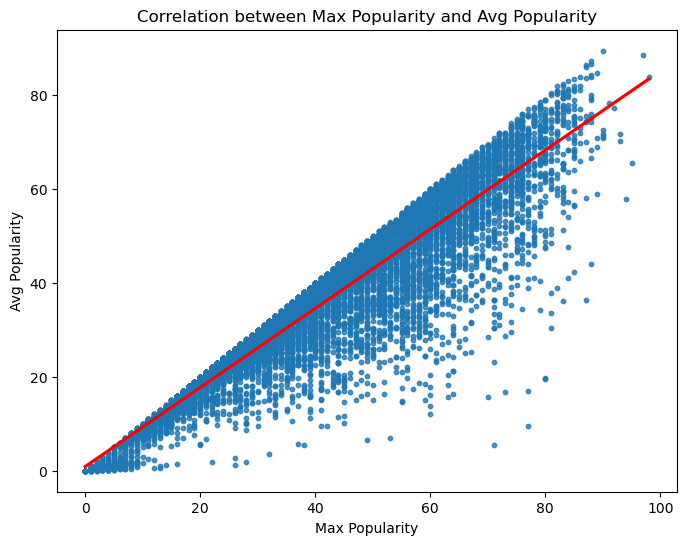

In [16]:
# Correlation between highest popularity of each album and mean popularity of each album 
plt.figure(figsize=(8, 6))
sns.regplot(x='max_popularity', y='avg_popularity', data=album_stats, scatter_kws={'s': 10}, line_kws={'color': 'red'})
plt.title('Correlation between Max Popularity and Avg Popularity')
plt.xlabel('Max Popularity')
plt.ylabel('Avg Popularity')
plt.show()

Positive Relationship: As the max_popularity (the most popular track in an album) increases, the avg_popularity (the average popularity of all tracks in the album) also increases. This indicates that highly popular tracks are associated with higher popularity for the rest of the album.

Presence of Highly Popular Tracks: The presence of a highly popular song in an album seems to positively influence the popularity of other tracks in the album. This could be due to several factors:

- Listener Engagement: When listeners find a highly popular track, they may explore the other tracks in the album, which can lead to higher engagement and popularity for those tracks as well.
- Algorithm: Platforms like Spotify may recommend other tracks from the same album when a user listens to a highly popular track, boosting the visibility and popularity of the rest of the album.
- Cohesive Album Appeal: Popular albums often have a cohesive style or genre that appeals to listeners, and a hit song can draw attention to the entire album, raising the popularity of its other tracks.

The regression line in the plot supports this view with correlation of 0.949, showing a consistent increase in average popularity as maximum popularity rises, reinforcing the idea that a highly popular track can positively impact the overall reception of an album.

<h1>POPULARITY DISTRIBUTION BETWEEN TWO ALBUM</h1>

In [19]:
# Calculate 75th percentile of popularity
popularity_75th_percentile = df_filtered['popularity'].quantile(0.75)

# Filter albums where track has popularity >= 75th percentile
albums_with_popular_tracks = df_filtered[df_filtered['popularity'] >= popularity_75th_percentile]['album_name'].unique()

# Filter to include only albums that have track with popularity >= 75th percentile
filtered_df = df_filtered[df_filtered['album_name'].isin(albums_with_popular_tracks)]

# Group by album_name and count the number of tracks in each album
album_track_counts = filtered_df.groupby('album_name').size()

# Sort the album counts in descending order
sorted_album_track_counts = album_track_counts.sort_values(ascending=False)

# Output the sorted result
print(sorted_album_track_counts)

album_name
the complete hank williams           110
greatest hits                         77
ao vivo                               59
nursery rhymes by cocomelon           40
awake                                 39
                                    ... 
noor                                   2
normal                                 2
nossa dança                            2
nosso (ao vivo)                        2
공감 (empathy) - the 1st mini album      2
Length: 5448, dtype: int64


In [20]:
# Filter DataFrame for album 'greatest hits'
album = df_filtered[df_filtered['album_name'] == 'greatest hits']

# Check number of tracks popularity above 75th percentile
(album['popularity'] >= df_filtered['popularity'].quantile(0.75)).sum()

26

In [21]:
# Filter DataFrame for album 'the complete hank williams'
album = df_filtered[df_filtered['album_name'] == 'the complete hank williams']

# Check number of tracks popularity above 75th percentile
(album['popularity'] >= df_filtered['popularity'].quantile(0.75)).sum()

2

In [22]:
# Filter album
greatest_hits = df_filtered[df_filtered['album_name'] == 'greatest hits']
hank_williams = df_filtered[df_filtered['album_name'] == 'the complete hank williams']

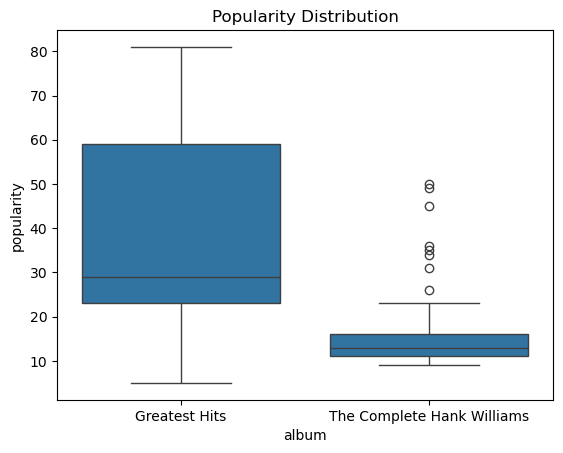

In [23]:
# Plot popularity distribution between two album
comparison_data = pd.concat([
    greatest_hits[['popularity']].assign(album='Greatest Hits'),
    hank_williams[['popularity']].assign(album='The Complete Hank Williams')
])

sns.boxplot(x='album', y='popularity', data=comparison_data)
plt.title('Popularity Distribution')
plt.show()

The box for "Greatest Hits" shows a much larger range of popularity scores compared to "The Complete Hank Williams." This indicates that "Greatest Hits" has both highly popular songs and less popular songs, this could mean that with a very popular track within an album, listener engage more into other tracks within album leading to overall a wider variability in listener engagement.

The median popularity in "Greatest Hits" is higher than in "The Complete Hank Williams." This suggests that tracks in "Greatest Hits" generally have higher popularity scores, potentially indicating that the presence of highly popular songs may elevate the overall appeal or discovery of the other tracks.

The popularity scores for "The Complete Hank Williams" are concentrated within a narrower range with a lower overall median. This could suggest that the album lacks the pull of highly popular tracks that might drive engagement with the other songs Even with popular song in the outliers, indicating that some tracks achieved relatively higher popularity compared to the rest of the album, these tracks may be standout hits, but their impact on the popularity of other tracks seems limited compared to the effect seen in "Greatest Hits."

<h1>POPULARITY DIFFERENCE DISTRIBUTION BETWEEN TWO ALBUM </h1>

In [26]:
df_filtered = df_filtered.copy()
# Show the highest popularity each track currently have within their album 
df_filtered['max_popularity'] = df_filtered.groupby('album_name')['popularity'].transform("max")

# Difference between the track with highest popularity against other tracks within album
df_filtered['difference'] = df_filtered['max_popularity'] - df_filtered['popularity']

In [27]:
# Filter album
greatest_hits = df_filtered[df_filtered['album_name'] == 'greatest hits']
hank_williams = df_filtered[df_filtered['album_name'] == 'the complete hank williams']

In [28]:
# sort the differences between max popularity and other tracks within album to visualize the spread
greatest_hits['difference'].value_counts().sort_index(ascending=True)

difference
0     1
2     1
8     1
9     2
11    1
12    1
13    1
14    3
16    1
17    1
19    3
20    1
21    2
22    2
23    1
25    1
26    2
34    1
40    1
41    2
43    1
44    1
45    1
49    2
50    2
52    4
53    1
54    2
55    2
56    2
57    7
58    8
59    4
60    2
62    1
65    2
66    1
67    1
68    1
72    1
75    1
76    1
Name: count, dtype: int64

In [29]:
# sort the differences between track with highest popularity and other tracks within album to visualize the spread
hank_williams['difference'].value_counts().sort_index(ascending=True)

difference
0      1
1      1
5      1
14     1
15     1
16     1
19     1
24     1
27     1
28     1
29     1
30     3
31     4
32     3
34    10
35     9
36     6
37    13
38    15
39    17
40    15
41     4
Name: count, dtype: int64

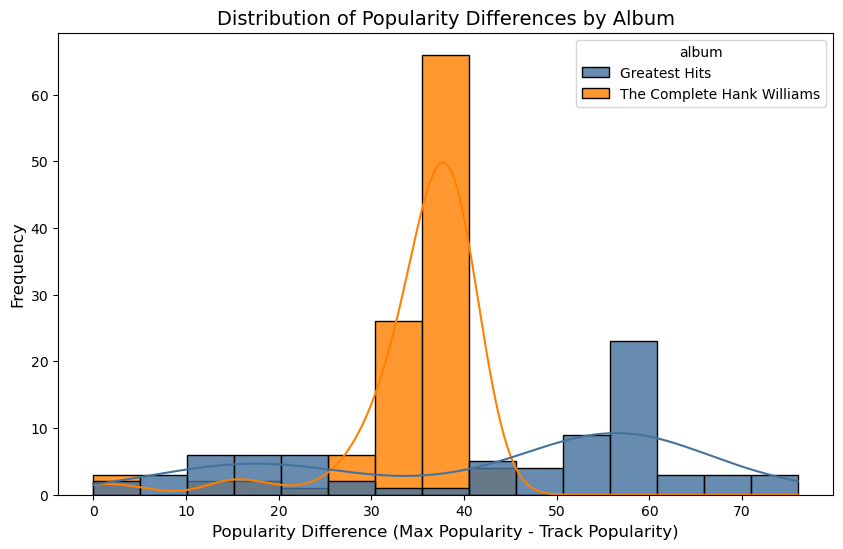

In [268]:
# Filter data for the two albums
greatest_hits = df_filtered[df_filtered['album_name'] == 'greatest hits']
hank_williams = df_filtered[df_filtered['album_name'] == 'the complete hank williams']

# Concatenate two album into one new dataframe
comparison_data = pd.concat([
    greatest_hits[['difference']].assign(album='Greatest Hits'),
    hank_williams[['difference']].assign(album='The Complete Hank Williams')
])

# Set the default Seaborn color palette
#sns.set_palette(sns.color_palette("tab10"))

# Change color for consistency
custom_palette = {'Greatest Hits': '#44729D', 'The Complete Hank Williams': '#FF8000'}

# figure size 
plt.figure(figsize=(10, 6))

# Plot track diffrence within album
sns.histplot(data=comparison_data, x='difference', hue='album', kde=True, bins=15, palette=custom_palette, alpha=0.81)

# Add titles and labels
plt.title('Distribution of Popularity Differences by Album', fontsize=14)
plt.xlabel('Popularity Difference (Max Popularity - Track Popularity)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Show the plot
plt.show()

The greatest_hits album appears to have a wider spread, with more tracks leans toward the most popular song. This suggests that more songs are being explored, resulting in a broader range of differences. In contrast, the hank_williams album seems to exhibit a tighter distribution, indicating lower engagement with its less popular tracks.

This disparity could be influenced by recommendation algorithms, where highly popular songs are often associated with genres that appeal to a broader audience. Greatest Hits has 21 unique genre, compare to Hank Williams with 1 niche genre call 'Honky Tonk'. Tracks in Greatest Hits may gain more exposure because of more genre variety of popular song, driving further exploration of the album, and psychological factors, such as momentum in listening behavior. When a standout song captures a listener's attention or evokes a strong emotional response, it can motivate them to continue exploring the album, anticipating a similar experience with other tracks. This momentum builds as listeners, encouraged by a positive start, are more inclined to continue listening, so particularly enjoyable track can create a favorable impression of the entire album, prompting further exploration even if some tracks are less immediately appealing.

<h1> POPULARITY AND DIFFRENCE CORRELATION</h1>

In [33]:
# Number of genre exist within album
greatest_hits['track_genre'].value_counts()

track_genre
power-pop        15
hardcore         10
honky-tonk        7
psych-rock        6
chicago-house     5
synth-pop         5
funk              5
country           4
disco             3
new-age           2
bluegrass         2
hard-rock         2
grunge            2
techno            2
cantopop          1
j-pop             1
comedy            1
rock-n-roll       1
rockabilly        1
ska               1
children          1
Name: count, dtype: int64

In [34]:
# Number of tracks above 75th percentile
popular_gh = greatest_hits[greatest_hits['popularity'] >= greatest_hits['popularity'].quantile(0.75)]
# Number of genre of the hit song
popular_gh['track_genre'].value_counts()

track_genre
hardcore      6
funk          5
country       3
synth-pop     2
disco         1
grunge        1
power-pop     1
psych-rock    1
techno        1
Name: count, dtype: int64

In [35]:
# Aggregate data by genre
genre_aggregated = greatest_hits.groupby('track_genre').agg({'popularity': 'mean', 'difference': 'mean'})

print(genre_aggregated)

               popularity  difference
track_genre                          
bluegrass       22.000000   59.000000
cantopop        23.000000   58.000000
chicago-house   14.200000   66.800000
children        29.000000   52.000000
comedy          23.000000   58.000000
country         61.500000   19.500000
disco           44.333333   36.666667
funk            73.400000    7.600000
grunge          45.500000   35.500000
hard-rock       38.500000   42.500000
hardcore        59.200000   21.800000
honky-tonk      20.571429   60.428571
j-pop           40.000000   41.000000
new-age         23.500000   57.500000
power-pop       26.000000   55.000000
psych-rock      32.666667   48.333333
rock-n-roll     29.000000   52.000000
rockabilly      24.000000   57.000000
ska             37.000000   44.000000
synth-pop       45.400000   35.600000
techno          46.500000   34.500000


In [36]:
# Pearson Correlation between popularity and difference grouped by genre 
genre_popularity_corr = greatest_hits.groupby('track_genre').agg({'popularity': 'mean', 'difference': 'mean'}).corr()
genre_popularity_corr

,popularity,difference
popularity,1.0,-1.0
difference,-1.0,1.0


A correlation of -1.0 indicates a perfect negative correlation. This means that, as the popularity of a track increases, the difference decreases (or becomes more negative). In other words, as the popularity of a track approaches the maximum within an album, the difference from the maximum popularity becomes smaller (closer to 0). This is an indicator that that more popular tracks are less likely to differ greatly from the most popular track in an album.

<h1> POPULARITY ENGAGEMENT OF HIT VS NON HIT BY GENRE </h1>

In [40]:
greatest_hits = greatest_hits.copy()
# assign tracks 'is_hit' if popularity greater than 75th percentile
greatest_hits['is_hit'] = greatest_hits.groupby('album_name')['popularity'].transform(lambda x: x > x.quantile(0.75))
genre_engagement = greatest_hits.groupby(['track_genre', 'is_hit'])['popularity'].mean().reset_index()
genre_engagement

,track_genre,is_hit,popularity
0,bluegrass,False,22.000000
1,cantopop,False,23.000000
2,chicago-house,False,14.200000
3,children,False,29.000000
4,comedy,False,23.000000
5,country,False,47.000000
6,country,True,66.333333
7,disco,False,31.500000
8,disco,True,70.000000
9,funk,True,73.400000


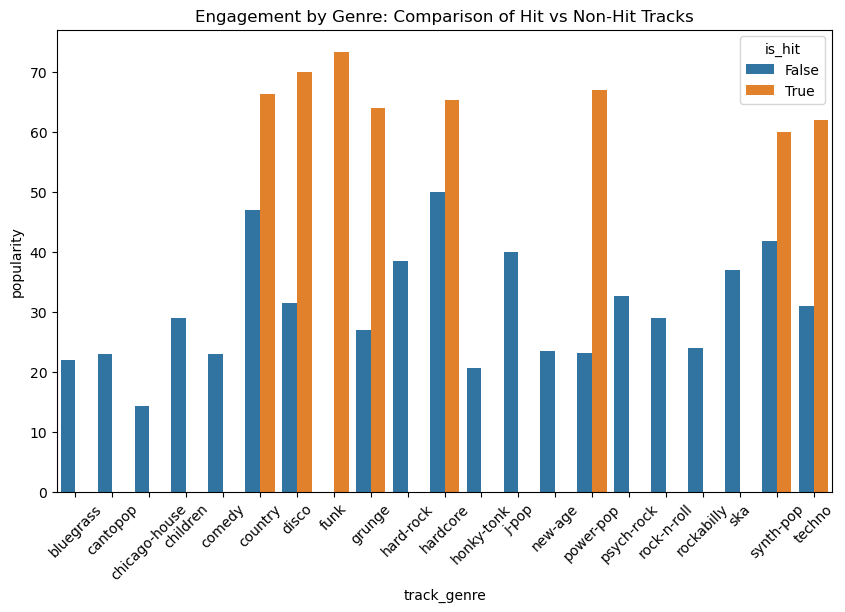

In [44]:
# Plot the engagement distribution effect of hit tracks on non-hit tracks within album
plt.figure(figsize=(10, 6))
sns.barplot(x='track_genre', y='popularity', hue='is_hit', data=genre_engagement)
plt.xticks(rotation=45)
plt.title('Engagement by Genre: Comparison of Hit vs Non-Hit Tracks')
plt.show()

This bar plot visualizes track engagement within albums, grouped by genre, to explore how the popularity of hit songs within a genre influences the popularity of non-hit songs in the same genre. The results show that genres with non-hit songs tend to have popularity levels that are not drastically lower than their hit counterparts, suggesting that highly popular songs can positively influence the popularity of non-hit tracks within the same genre. However, certain genres, such as disco, techno, grunge, and new age, show less influence because it may be attributed to their subjective nature. These genres often feature distinct musical styles that may not appeal to everyone, making them polarizing where the song either has to be very good or they won't listen to such genre. For some, these styles might feel unconventional compared to more traditional genres like country, funk, rock, or pop music, which tend to have broader appeal.

<h1>HEATMAP ATTRIBUTES</h1>

In [48]:
# Sort by popularity in descending order and get the top 10 rows within album
top_10_popular = greatest_hits.sort_values(by='popularity', ascending=False).head(10)
top_10_popular

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,all_genres,duration_min,artist_count,max_popularity,difference,is_hit
33616,0Z2J91b2iTGLVTZC4fKgxf,2Pac;Outlawz,greatest hits,Hit 'Em Up - Single Version,81,312626,True,0.916,0.844,7,-3.967,1,0.2360,0.0394,0.000000,0.0778,0.586,95.190,4,funk,funk,5.210433,2,81,0,True
33652,3ia3dJETSOllPsv3LJkE35,2Pac;Roger;Dr. Dre,greatest hits,California Love - Original Version,79,284906,True,0.763,0.850,7,-3.052,1,0.0417,0.0304,0.000001,0.3710,0.761,91.519,4,funk,funk,4.748433,3,81,2,True
33786,1ofhfV90EnYhEr7Un2fWiv,2Pac;Talent,greatest hits,Changes,73,268826,True,0.865,0.665,7,-6.289,1,0.0730,0.0453,0.000000,0.2240,0.331,111.113,4,funk,funk,4.480433,2,81,8,True
42560,63BcfK6YAzJYeISaTPr6IO,The Notorious B.I.G.,greatest hits,Big Poppa - 2007 Remaster,72,249866,True,0.765,0.671,9,-5.249,0,0.2780,0.3440,0.000000,0.0506,0.798,84.500,4,hardcore,hardcore,4.164433,1,81,9,True
42558,6Tsu3OsuMz4KEGKbOYd6A0,The Notorious B.I.G.,greatest hits,Hypnotize - 2007 Remaster,72,230000,True,0.895,0.694,9,-4.384,1,0.2750,0.1760,0.000000,0.2920,0.632,93.944,4,hardcore,hardcore,3.833333,1,81,9,True
24165,569uHYIB0X324FZOBEhvit,Ray Parker Jr.,greatest hits,Ghostbusters,70,239133,False,0.778,0.719,4,-9.698,1,0.0345,0.0123,0.026200,0.2970,0.729,115.400,4,disco,disco,3.985550,1,81,11,True
18769,7BD50ATrF3Vab5FQy7vtK8,LeAnn Rimes,greatest hits,How Do I Live,69,266973,False,0.577,0.462,2,-7.989,1,0.0279,0.1280,0.000000,0.0822,0.258,128.303,4,country,country,4.449550,1,81,12,True
18593,0vswnzoKvhNkT1ehc0Tt19,Shania Twain,greatest hits,From This Moment On - Pop On-Tour Version,68,235106,False,0.460,0.505,9,-5.487,1,0.0266,0.4200,0.000000,0.1340,0.220,135.757,4,country,country,3.918433,1,81,13,True
68057,7bOYOD0d7ByMTXvJnQVl8d,Blondie,greatest hits,Maria,67,249426,False,0.548,0.800,9,-6.926,1,0.0597,0.0380,0.002550,0.0678,0.805,159.654,4,power-pop,power-pop,4.157100,1,81,14,True
34037,2zoobJFEB9h15fjYjRd6oP,2Pac,greatest hits,Hail Mary,67,312373,True,0.772,0.644,10,-6.318,0,0.2650,0.1580,0.000004,0.3660,0.388,82.050,4,funk,funk,5.206217,1,81,14,True


In [49]:
# Sort the entire dataset by 'popularity' in descending order
df_sorted = df_filtered.sort_values(by='popularity', ascending=False).reset_index(drop=True)

# Add 'rank' column (rank starts at 1)
df_sorted['rank'] = df_sorted.index + 1

# Filter top 10 track IDs
top_10_track_ids = ['0Z2J91b2iTGLVTZC4fKgxf', '3ia3dJETSOllPsv3LJkE35', '1ofhfV90EnYhEr7Un2fWiv', '63BcfK6YAzJYeISaTPr6IO', '6Tsu3OsuMz4KEGKbOYd6A0', 
                    '569uHYIB0X324FZOBEhvit', '7BD50ATrF3Vab5FQy7vtK8', '0vswnzoKvhNkT1ehc0Tt19', '7bOYOD0d7ByMTXvJnQVl8d', '2zoobJFEB9h15fjYjRd6oP']  
global_ranking = df_sorted[df_sorted['track_id'].isin(top_10_track_ids)]

# Ranking of top 10 tracks
global_ranking

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,all_genres,duration_min,artist_count,max_popularity,difference,rank
257,0Z2J91b2iTGLVTZC4fKgxf,2Pac;Outlawz,greatest hits,Hit 'Em Up - Single Version,81,312626,True,0.916,0.844,7,-3.967,1,0.2360,0.0394,0.000000,0.0778,0.586,95.190,4,funk,funk,5.210433,2,81,0,258
359,3ia3dJETSOllPsv3LJkE35,2Pac;Roger;Dr. Dre,greatest hits,California Love - Original Version,79,284906,True,0.763,0.850,7,-3.052,1,0.0417,0.0304,0.000001,0.3710,0.761,91.519,4,funk,funk,4.748433,3,81,2,360
1098,1ofhfV90EnYhEr7Un2fWiv,2Pac;Talent,greatest hits,Changes,73,268826,True,0.865,0.665,7,-6.289,1,0.0730,0.0453,0.000000,0.2240,0.331,111.113,4,funk,funk,4.480433,2,81,8,1099
1235,6Tsu3OsuMz4KEGKbOYd6A0,The Notorious B.I.G.,greatest hits,Hypnotize - 2007 Remaster,72,230000,True,0.895,0.694,9,-4.384,1,0.2750,0.1760,0.000000,0.2920,0.632,93.944,4,hardcore,hardcore,3.833333,1,81,9,1236
1249,63BcfK6YAzJYeISaTPr6IO,The Notorious B.I.G.,greatest hits,Big Poppa - 2007 Remaster,72,249866,True,0.765,0.671,9,-5.249,0,0.2780,0.3440,0.000000,0.0506,0.798,84.500,4,hardcore,hardcore,4.164433,1,81,9,1250
1713,569uHYIB0X324FZOBEhvit,Ray Parker Jr.,greatest hits,Ghostbusters,70,239133,False,0.778,0.719,4,-9.698,1,0.0345,0.0123,0.026200,0.2970,0.729,115.400,4,disco,disco,3.985550,1,81,11,1714
1768,7BD50ATrF3Vab5FQy7vtK8,LeAnn Rimes,greatest hits,How Do I Live,69,266973,False,0.577,0.462,2,-7.989,1,0.0279,0.1280,0.000000,0.0822,0.258,128.303,4,country,country,4.449550,1,81,12,1769
1989,0vswnzoKvhNkT1ehc0Tt19,Shania Twain,greatest hits,From This Moment On - Pop On-Tour Version,68,235106,False,0.460,0.505,9,-5.487,1,0.0266,0.4200,0.000000,0.1340,0.220,135.757,4,country,country,3.918433,1,81,13,1990
2452,2zoobJFEB9h15fjYjRd6oP,2Pac,greatest hits,Hail Mary,67,312373,True,0.772,0.644,10,-6.318,0,0.2650,0.1580,0.000004,0.3660,0.388,82.050,4,funk,funk,5.206217,1,81,14,2453
2453,7bOYOD0d7ByMTXvJnQVl8d,Blondie,greatest hits,Maria,67,249426,False,0.548,0.800,9,-6.926,1,0.0597,0.0380,0.002550,0.0678,0.805,159.654,4,power-pop,power-pop,4.157100,1,81,14,2454


In [50]:
# Top 10 track within album - artists
top_10_popular['artists'].value_counts()

artists
The Notorious B.I.G.    2
2Pac;Outlawz            1
2Pac;Roger;Dr. Dre      1
2Pac;Talent             1
Ray Parker Jr.          1
LeAnn Rimes             1
Shania Twain            1
Blondie                 1
2Pac                    1
Name: count, dtype: int64

In [51]:
# Top 10 track within album - explicitness 
top_10_popular['explicit'].value_counts()

explicit
True     6
False    4
Name: count, dtype: int64

In [52]:
# Top 10 track within album - genre 
top_10_popular['track_genre'].value_counts()

track_genre
funk         4
hardcore     2
country      2
disco        1
power-pop    1
Name: count, dtype: int64

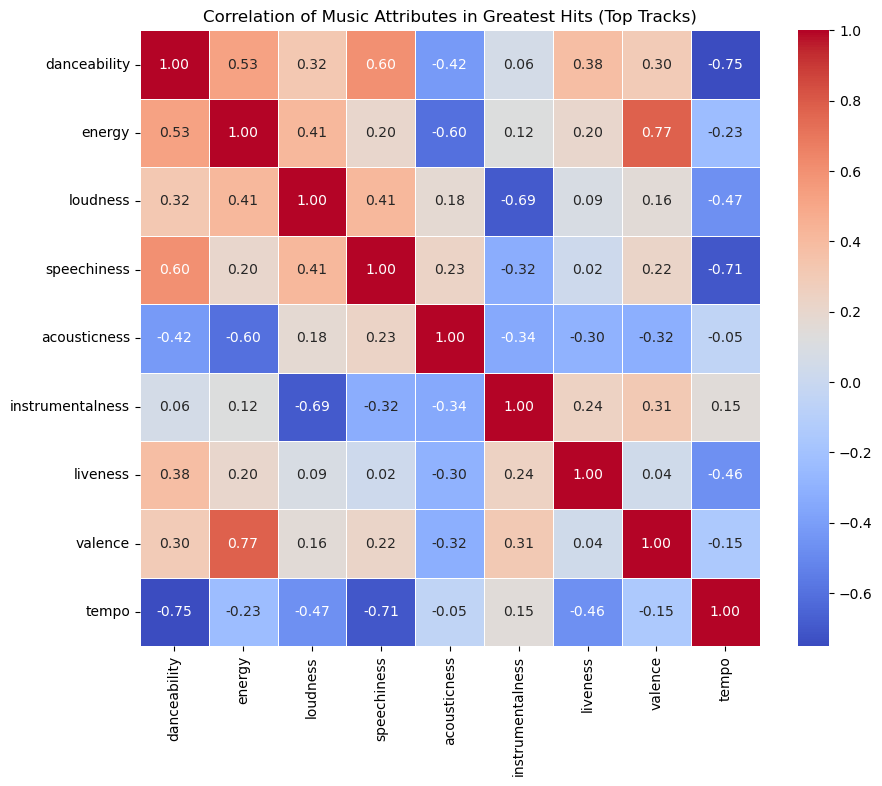

In [53]:
# Select music-related attributes for correlation analysis
attributes = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 
    'valence', 'tempo'
]

# Compute correlation matrix for selected attributes
correlation_matrix = top_10_popular[attributes].corr()

# Visualize the correlation matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation of Music Attributes in Greatest Hits (Top Tracks)')
plt.show()

2Pac and The Notorious B.I.G. are iconic figures in rap and have a strong presence among the top 5 hit songs within the greatest_hits album. This highlights the significant influence of hip-hop on the album's popularity. However, in the dataset, the genre for these tracks is labeled as "funk" and "hardcore" which seems to be a popular rap genre in the old days.

There is a strong negative correlation (-0.75) between danceability and tempo. This suggests that tracks with higher danceability tend to have slower tempos, while tracks with faster tempos tend to be less danceable. Interestingly, the dataset assigns danceability scores to hip-hop songs are comparable to or higher than disco tracks, which seems unusual. This raises concerns about potential bias or inaccuracies in the genre classification, as seen with hip-hop tracks being labeled "funk" and "hardcore." I also try to play the song on spotify, and I dont see the rap song are danceable, so we need more context to understand the factor on evaluation. 

For high acousticness and lower energy (-0.60), country song often focus on storytelling which can make sense on low danceability score despite having tempos that fall between rap and disco, further explaining the negative correlation. 

Another strong negative correlation (-0.71) is observed between tempo and speechiness. This trend is largely influenced by the dominance of rap songs in the dataset, where 6 out of 10 tracks have lower tempos and higher speechiness compared to genres like country, disco, and power pop, which exhibit lower speechiness and significantly higher tempos.

Valence, reflecting the mood of a track, shows a strong positive correlation (0.77) with energy. This suggests that tracks with higher energy often convey a more positive or upbeat mood. This is common in rap tracks that prioritize energy and mood in their delivery, as well as disco songs, known for its upbeat tempo, smooth rhythm, and danceable qualities. A clear correlation we could observe from the top 10 tracks is with power pop track, with their catchy melodies and strong rhythms, exhibit energy and valence levels around 0.80, while country songs generally have lower energy (0.50) and valence (0.25).

Instrumentalness has weak correlations with most attributes but is notably negatively correlated with loudness (-0.69). Generally, instrumental tracks tend to be softer and less energetic, which contrasts with rap's vocal-centric style. Similar to disco, which often uses electronic sounds, tends to be loud beats and less instrumental tracks. On the other hand, country music, with its higher acoustic elements, aligns with the quieter nature of instrumental tracks.

Overall, by evaluating the attributes of top 10 tracks, we could see that 6 out 10 tracks are 'funk' and 'hardcore' aka hip hop. What I derive from the attributes correlation is 

- Valence and Energy Correlation (0.77): Most popular songs within album by 2Pac - "Hit Em Up" likely exhibit high energy and valence, creating a mood that engages listeners. This upbeat and positive tone can make listeners stay and explore other tracks that carry similar energy or complement the album's overall mood, thus, results in top 5 tracks being same genre.
- Even with negative correlation betweeen instrumentalness and loudness (-0.69), albums featuring popular loud, vocal tracks (rap or disco) might retain listeners, who then discover quieter, instrumental tracks, like country music with more acousticness and quieter nature can provide contrast and balance, keeping the listener's interest.
- The dominance of hiphop in the dataset (6 out of 10) highlights a pattern that rap tracks with high speechiness and lower tempo (-0.71) stand out, driving engagement. Popular tracks might introduce listeners to this pattern, encouraging them to explore other songs with similar qualities. They also have high speechiness and moderate danceability (0.60) which may attract an audience seeking lyrical depth. These listeners could then be exposed to disco or country-inspired tracks with contrasting moods and tempos, fostering cross-genre engagement.

To conclude, presence of highly popular songs in an album acts as a gateway for audience engagement, exposing listeners to less popular tracks and increasing overall album streams. Attributes like valence, energy, and danceability, along with contrasts in tempo or mood, help maintain listener interest throughout the album. This synergy between tracks explains how a few standout songs can elevate the album's overall popularity.